# Lightning-Caused Wildfire Detection: Results

This notebook gathers every result produced so far for the August 2020 California lightning siege. It only **reads** the data and result files in this folder, except for re-running the fast matching and validation steps (a few seconds) so their output is shown here.

**Contents**
1. Data overview
2. Matching prototype
3. Chance baseline and parameter tuning
4. Validation against FPA FOD
5. Streaming pipeline benchmarks
6. Precision/recall trade-off
7. MongoDB geospatial queries
8. Largest recorded lightning fires
9. Broader evaluation: Aug 15–25 and CAL FIRE perimeters
10. MongoDB vs Snowflake
11. Course techniques
12. Status and next steps

See `README.md` for how each file was produced.

In [1]:
import os, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
BLUE, ORANGE, RED, GREY, TEAL = "#2563eb", "#f59e0b", "#dc2626", "#9ca3af", "#0d9488"

def load(name, **kw):
    if os.path.exists(name):
        return pd.read_csv(name, **kw)
    print(f"Missing {name}: see README for the step that creates it.")
    return None

def run(*args):
    out = subprocess.run([sys.executable, *args], capture_output=True, text=True)
    print(out.stdout[out.stdout.find("====="):] if "=====" in out.stdout else out.stdout + out.stderr)

## 1. Data overview

In [2]:
firms = load("firms_aug2020.csv")
hhmm = firms["acq_time"].astype(int).astype(str).str.zfill(4)
firms["time"] = (pd.to_datetime(firms["acq_date"]) + pd.to_timedelta(hhmm.str[:2].astype(int), unit="h")
                 + pd.to_timedelta(hhmm.str[2:].astype(int), unit="m"))
glm = load("glm_aug2020.csv", parse_dates=["flash_time"])
fod = load("fpa_fod_ca_lightning.csv")
fod["date"] = pd.to_datetime(fod["FIRE_YEAR"].astype(str)) + pd.to_timedelta(fod["DISCOVERY_DOY"] - 1, unit="D")

pd.DataFrame([
    ["FIRMS VIIRS fire detections", f"{firms.time.min():%b %d} to {firms.time.max():%b %d, %Y}", f"{len(firms):,}"],
    ["  ...nominal or high confidence", "", f"{(firms.confidence.astype(str).str.lower() != 'l').sum():,}"],
    ["GOES-17 GLM flashes over California", f"{glm.flash_time.min():%b %d} to {glm.flash_time.max():%b %d, %Y}", f"{len(glm):,}"],
    ["FPA FOD natural-cause fires, California", "2019-2020", f"{len(fod):,}"],
    ["  ...discovered Aug 15-22, 2020", "", f"{fod.date.between('2020-08-15', '2020-08-22').sum():,}"],
], columns=["Dataset", "Window", "Records"]).style.hide(axis="index")

Dataset,Window,Records
FIRMS VIIRS fire detections,"Aug 08 to Aug 25, 2020","44,022"
...nominal or high confidence,,"41,647"
GOES-17 GLM flashes over California,"Aug 15 to Aug 20, 2020","60,803"
"FPA FOD natural-cause fires, California",2019-2020,"1,096"
"...discovered Aug 15-22, 2020",,242


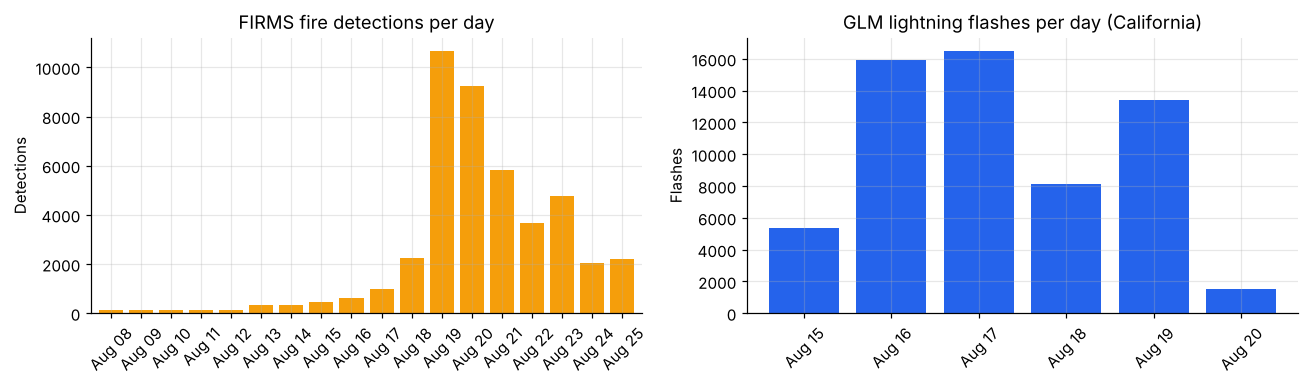

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
firms.groupby(firms.time.dt.date).size().plot.bar(ax=axes[0], color=ORANGE, width=0.8)
axes[0].set(title="FIRMS fire detections per day", xlabel="", ylabel="Detections")
glm.groupby(glm.flash_time.dt.date).size().plot.bar(ax=axes[1], color=BLUE, width=0.8)
axes[1].set(title="GLM lightning flashes per day (California)", xlabel="", ylabel="Flashes")
for ax in axes:
    ax.set_xticklabels([pd.Timestamp(t.get_text()).strftime("%b %d") for t in ax.get_xticklabels()], rotation=45)
plt.tight_layout(); plt.show()

Lightning peaked on Aug 16–17. Fire detections exploded a day or two later as the ignitions grew. That delay is why the matching looks *back* in time from each fire.

## 2. Matching prototype (D = 5 km, T = 48 h, new-fire rule 5 km)

In [4]:
run("match_prototype.py", "--d-km", "5", "--t-hours", "48", "--new-km", "5")

===== MATCHING SUMMARY =====
Parameters:   D = 5.0 km, T = 48.0 h; 'new fire' = nothing within 5.0 km in prior 7 days
Fire detections (nominal/high confidence):  41,647
New fires since 2020-08-15:                159
GLM flashes in sample:                      60,803  (2020-08-15 00:00:01.218433856 to 2020-08-20 23:59:46.772336959 UTC)
New fires within the flash sample's window: 139
New fires with >=1 candidate flash:          65  (47% of those in the window)
Median nearest-flash distance:              1.8 km
Median fire-to-flash lag:                   20.1 h
Run time:                                   2.1 s
Saved: new_fires.csv, fire_flash_matches.csv



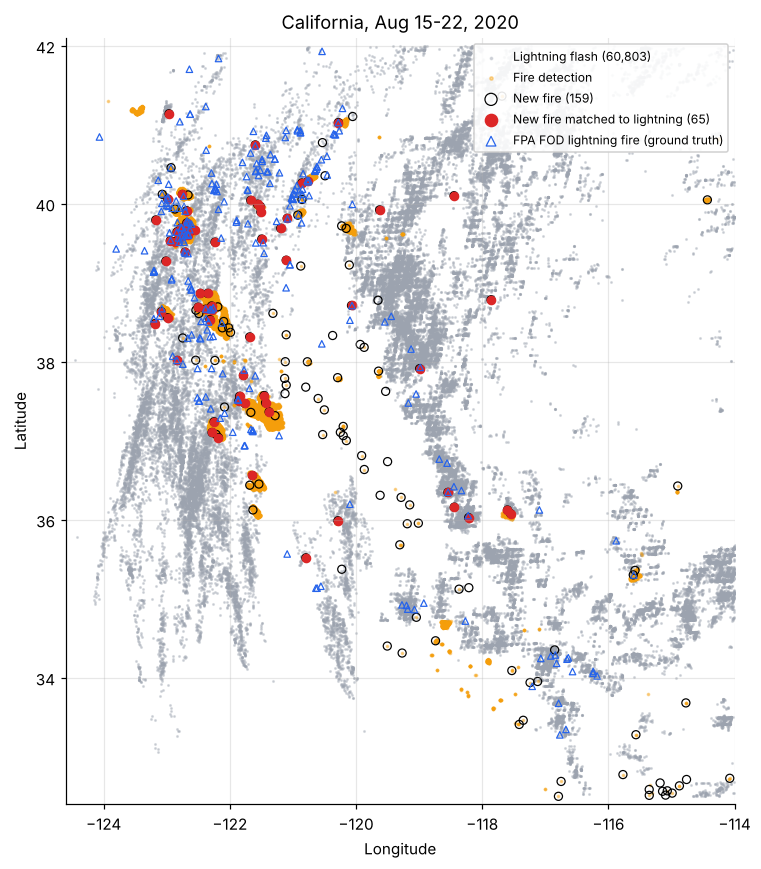

In [5]:
new = load("new_fires.csv", parse_dates=["time"])
matches = load("fire_flash_matches.csv", parse_dates=["fire_time"])
win = (firms.time >= "2020-08-15") & (firms.time < "2020-08-23")

fig, ax = plt.subplots(figsize=(7.5, 8))
ax.scatter(glm.lon, glm.lat, s=1, c=GREY, alpha=0.35, label=f"Lightning flash ({len(glm):,})")
ax.scatter(firms.longitude[win], firms.latitude[win], s=2, c=ORANGE, alpha=0.4, label="Fire detection")
ax.scatter(new.longitude, new.latitude, s=28, facecolors="none", edgecolors="black", lw=0.8, label=f"New fire ({len(new):,})")
ax.scatter(matches.fire_lon, matches.fire_lat, s=28, c=RED, label=f"New fire matched to lightning ({len(matches):,})")
ax.scatter(fod[fod.date.between("2020-08-15", "2020-08-22")].LONGITUDE,
           fod[fod.date.between("2020-08-15", "2020-08-22")].LATITUDE,
           s=18, marker="^", facecolors="none", edgecolors=BLUE, lw=0.8, label="FPA FOD lightning fire (ground truth)")
ax.set(xlim=(-124.6, -114), ylim=(32.4, 42.1), xlabel="Longitude", ylabel="Latitude",
       title="California, Aug 15-22, 2020")
ax.set_aspect(1 / np.cos(np.radians(37)))
ax.legend(loc="upper right", fontsize=8, markerscale=1.5, framealpha=0.9)
plt.tight_layout(); plt.show()

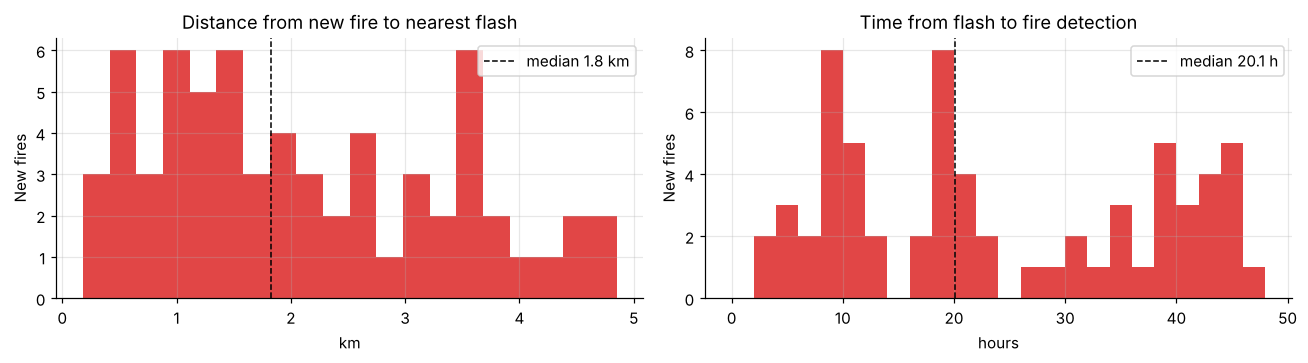

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].hist(matches.nearest_flash_km, bins=20, color=RED, alpha=0.85)
axes[0].axvline(matches.nearest_flash_km.median(), color="black", ls="--", lw=1,
                label=f"median {matches.nearest_flash_km.median():.1f} km")
axes[0].set(title="Distance from new fire to nearest flash", xlabel="km", ylabel="New fires")
axes[1].hist(matches.lag_hours, bins=24, range=(0, 48), color=RED, alpha=0.85)
axes[1].axvline(matches.lag_hours.median(), color="black", ls="--", lw=1,
                label=f"median {matches.lag_hours.median():.1f} h")
axes[1].set(title="Time from flash to fire detection", xlabel="hours", ylabel="New fires")
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()

Many matched fires were detected 12+ hours after the flash. That fits *holdover* fires that smoulder before they grow large enough to see, combined with VIIRS passing over only about twice a day. Distances under a few km should be read with caution, since GLM's location accuracy is about 8 km.

## 3. Chance baseline and parameter tuning

**Is the match rate better than coincidence?** During a lightning siege, flashes are dense, so a random fire may have one nearby by chance.

- *First attempt:* shuffling flash **times** gave a real rate of 44% versus 72% for chance. That baseline was **biased**: real lightning was concentrated on Aug 16–17, and shuffling spread it across all six days, closer to the later fires.
- *Fix:* a **spatial-shift baseline** keeps every flash's real time but moves the whole lightning field 50–100 km in a random direction (3 shifts per setting).

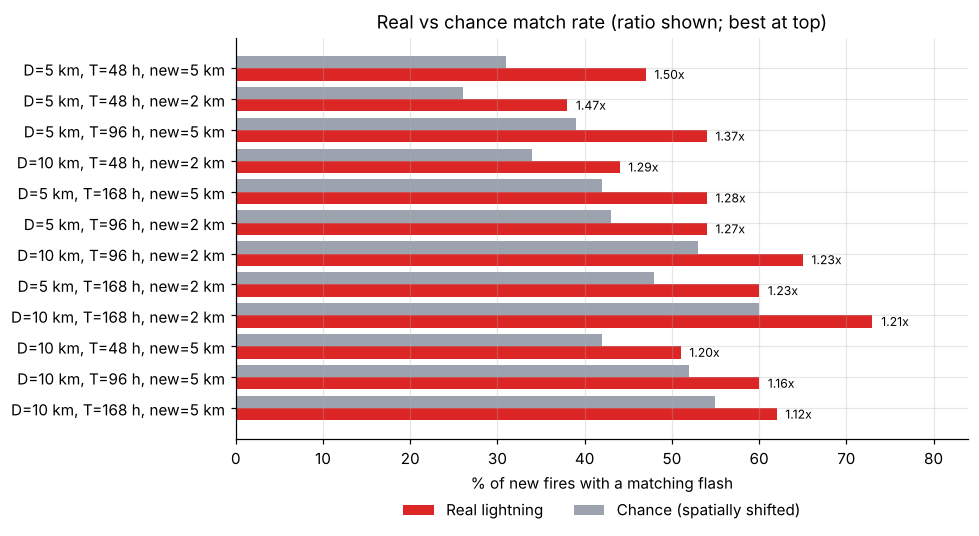

D_km,T_hours,new_fire_km,new_fires,real_rate,chance_rate,ratio
5,48,5,139,47%,31%,1.500000
5,48,2,305,38%,26%,1.470000
5,96,5,151,54%,39%,1.370000
10,48,2,305,44%,34%,1.290000
5,168,5,159,54%,42%,1.280000
5,96,2,337,54%,43%,1.270000
5,168,2,352,60%,48%,1.230000
10,96,2,337,65%,53%,1.230000
10,168,2,352,73%,60%,1.210000
10,48,5,139,51%,42%,1.200000


In [7]:
tune = load("tuning_results.csv")
tune["real"] = tune.real_rate.str.rstrip("%").astype(float)
tune["chance"] = tune.chance_rate.str.rstrip("%").astype(float)
tune["label"] = tune.apply(lambda r: f"D={r.D_km} km, T={r.T_hours} h, new={r.new_fire_km} km", axis=1)
t = tune.sort_values("ratio")

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(t))
ax.barh(y - 0.2, t.real, height=0.4, color=RED, label="Real lightning")
ax.barh(y + 0.2, t.chance, height=0.4, color=GREY, label="Chance (spatially shifted)")
for yi, (r, ratio) in enumerate(zip(t.real, t.ratio)):
    ax.text(r + 1, yi - 0.2, f"{ratio:.2f}x", va="center", fontsize=8)
ax.set(yticks=y, yticklabels=t.label, xlabel="% of new fires with a matching flash",
       xlim=(0, t.real.max() * 1.15), title="Real vs chance match rate (ratio shown; best at top)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout(); plt.show()
tune.drop(columns=["real", "chance", "label"]).style.hide(axis="index")

All 12 settings beat chance (1.12–1.50x). The best was **D = 5 km, T = 48 h, new-fire rule 5 km**: 47% real versus 31% chance. Widening D or T raises both rates, but chance rises faster.

## 4. Validation against FPA FOD ground truth

In [8]:
run("validate.py")

===== VALIDATION SUMMARY =====
Match rule: within 5 km and 2 days of a recorded fire; window 2020-08-15 to 2020-08-22
FPA FOD lightning fires in window:      242  (60 were 10+ acres)

                                        All new fires   Lightning-matched
Fires flagged by pipeline                         139                  65
Precision (near a recorded fire)                  23%                 38%
Recall, all recorded fires                        19%                 16%
Recall, fires 10+ acres                           48%                 37%
F1 score                                         0.21                0.23

Saved: validation_fires.csv (each recorded fire and whether the pipeline found it)



In [9]:
val = load("validation_fires.csv", parse_dates=["date"])
val["size_class"] = np.where(val.FIRE_SIZE >= 10, "10+ acres", "under 10 acres")
summary = val.groupby("size_class").found_by_pipeline.agg(recorded="size", found="sum")
summary["recall"] = (summary.found / summary.recorded).map("{:.0%}".format)
display(summary)
cols = [c for c in ["FIRE_NAME", "COMPLEX_NAME", "date", "FIRE_SIZE", "found_by_pipeline"] if c in val]
print("Largest recorded lightning fires in the window:")
val.sort_values("FIRE_SIZE", ascending=False)[cols].head(15).style.hide(axis="index")

,recorded,found,recall
size_class,,,
10+ acres,60,22,37%
under 10 acres,182,17,9%


Largest recorded lightning fires in the window:


FIRE_NAME,COMPLEX_NAME,date,FIRE_SIZE,found_by_pipeline
DOE,AUGUST COMPLEX,2020-08-16 00:00:00,589368.000000,True
HOPKINS,AUGUST COMPLEX,2020-08-17 00:00:00,328363.000000,False
CLAREMONT,NORTH COMPLEX,2020-08-17 00:00:00,318776.000000,False
HENNESSEY,LNU LIGHTNING COMPLEX,2020-08-17 00:00:00,305651.200000,True
CASTLE,SQF COMPLEX,2020-08-19 00:00:00,174178.000000,False
W-5 COLD SPRINGS,nan,2020-08-18 00:00:00,84817.000000,True
WALLBRIDGE,LNU LIGHTNING COMPLEX,2020-08-17 00:00:00,55209.000000,True
SHF ELKHORN,AUGUST COMPLEX,2020-08-18 00:00:00,51576.700000,True
DOME,nan,2020-08-15 00:00:00,43273.000000,False
SHEEP,NORTH COMPLEX,2020-08-17 00:00:00,29570.000000,True


The lightning filter raises precision from 23% to 38%. Recall is low overall because most recorded lightning fires were tiny, below what VIIRS can reliably detect, so recall on fires of 10+ acres is the fairer measure.

## 5. Streaming pipeline benchmarks

The Kafka → Spark Structured Streaming → MongoDB pipeline replayed 92,594 events (60,803 flashes and 31,791 fire detections) at three speeds, after 1,201 warm-up detections for Aug 8–14. Spark now runs **both rules inside the stream**: query 1 detects new fires with 7-day per-cell state and publishes them to a `new-fires` topic, and query 2 joins those new fires with lightning. At every speed it found **the same 139 new fires and the same 65 lightning matches as the pandas prototype (100% agreement on both)**.

"Spark peak" is the matcher's rate. The matcher now sees only flashes and new fires (60,942 events), so these peaks can't be compared directly with the Nov 12 run, which matched every raw detection (peak 28,809 events/s, median latency 3.3–6.7 s).

replay_speed,events,replay_time_s,producer_events_per_s,spark_peak_events_per_s,new_fires_detected,new_fire_agreement,new_fires_matched,agreement,latency_median_s,latency_p95_s,detect_latency_median_s
"3,600x",92594,188.800000,490,16405,139,100%,65,100%,7.500000,9.400000,3.700000
"36,000x",92594,19.000000,4880,25669,139,100%,65,100%,7.500000,9.200000,3.800000
max,92594,2.700000,34453,30959,139,100%,65,100%,7.100000,7.600000,5.300000


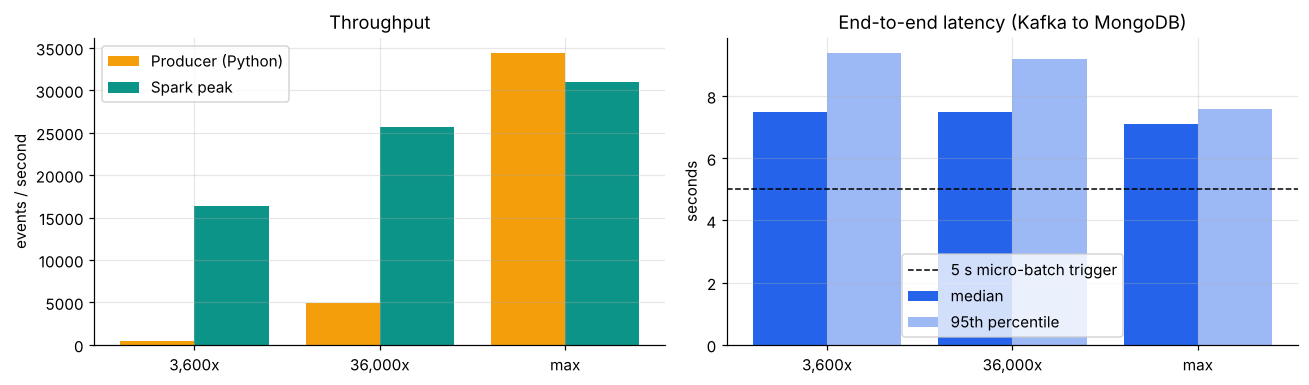

In [10]:
bench = load("benchmark_results.csv")
display(bench.style.hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
x = np.arange(len(bench))
axes[0].bar(x - 0.2, bench.producer_events_per_s, 0.4, color=ORANGE, label="Producer (Python)")
axes[0].bar(x + 0.2, bench.spark_peak_events_per_s, 0.4, color=TEAL, label="Spark peak")
axes[0].set(xticks=x, xticklabels=bench.replay_speed, ylabel="events / second", title="Throughput")
axes[0].legend()
axes[1].bar(x - 0.2, bench.latency_median_s, 0.4, color=BLUE, label="median")
axes[1].bar(x + 0.2, bench.latency_p95_s, 0.4, color=BLUE, alpha=0.45, label="95th percentile")
axes[1].axhline(5, color="black", ls="--", lw=1, label="5 s micro-batch trigger")
axes[1].set(xticks=x, xticklabels=bench.replay_speed, ylabel="seconds", title="End-to-end latency (Kafka to MongoDB)")
axes[1].legend()
plt.tight_layout(); plt.show()

End-to-end latency is now 7.1–7.5 s (median) because each fire passes through two 5-second micro-batch steps: the detector (median 3.7–5.3 s) and then the matcher. Throughput is still limited by the Python producer, not by Spark. The real event rate in this period averaged about 0.13 events per second, which leaves large headroom for real-time use.

## 6. Precision/recall trade-off against FPA FOD

`pr_sweep.py` reran the matching and validation for D = 2, 5 and 10 km and T = 24–168 h. Every setting beat the unfiltered baseline. 2 km was too tight for GLM's ~8 km location accuracy, and 48 h was the best time window. 5 km and 10 km performed about the same.

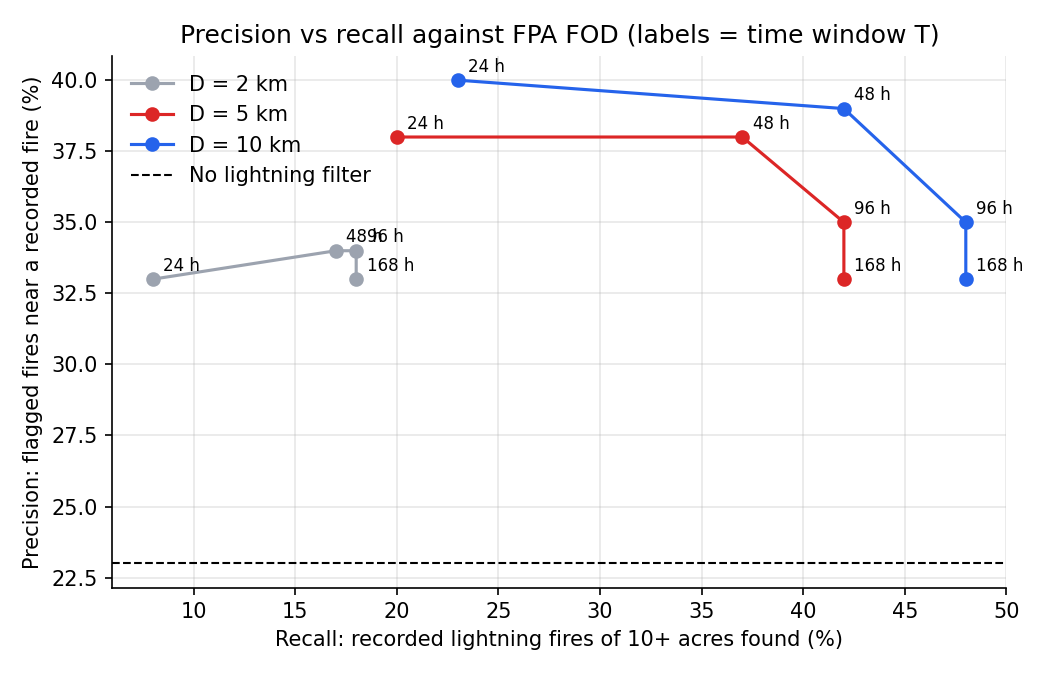

D_km,T_hours,fires_flagged,precision,recall_all,recall_10plus_acres,f1
10,96,91,35%,19%,48%,0.250000
10,48,71,39%,17%,42%,0.240000
10,168,97,33%,19%,48%,0.240000
5,48,65,38%,16%,37%,0.230000
5,96,81,35%,17%,42%,0.230000
5,168,84,33%,17%,42%,0.230000
10,24,42,40%,12%,23%,0.190000
5,24,39,38%,12%,20%,0.180000
2,96,38,34%,7%,18%,0.120000
2,168,39,33%,7%,18%,0.120000


In [11]:
sweep = load("pr_sweep.csv")
from IPython.display import Image
display(Image("pr_tradeoff.png", width=650))
show = sweep.sort_values("f1", ascending=False).copy()
for c in ["precision", "recall_all", "recall_10plus_acres"]:
    show[c] = (show[c] * 100).round().astype(int).astype(str) + "%"
show.style.hide(axis="index")

## 7. MongoDB geospatial queries

`mongo_bench.py` loaded the 60,803 flashes into MongoDB and, for each of the 139 new fires, queried for flashes within 5 km and the prior 48 h, with three index setups.

index,index_build_s,median_query_ms,p95_query_ms,total_s,avg_docs_examined,fires_matched
No index (full scan),0.000000,36.640000,41.030000,4.670000,60803,65
2dsphere on location,0.170000,0.570000,0.720000,0.080000,10,65
2dsphere + flash_time,0.170000,0.560000,0.700000,0.080000,6,65


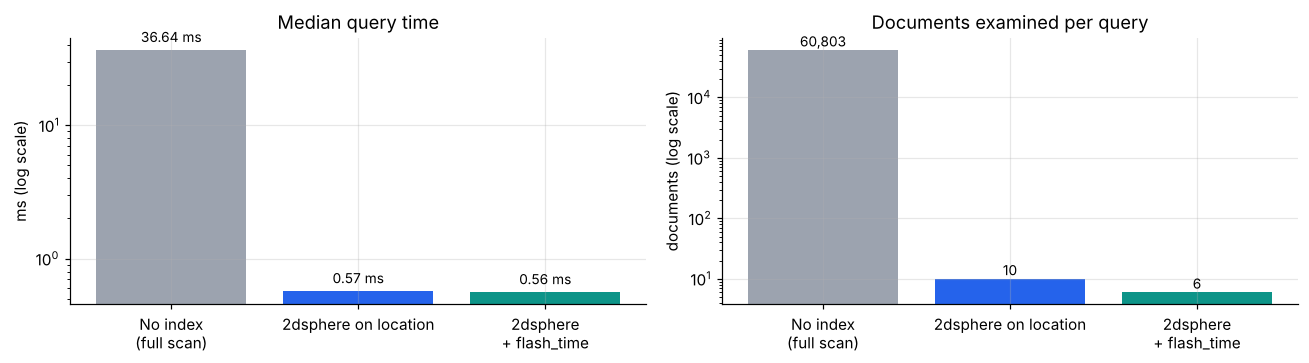

In [12]:
mongo = load("mongo_benchmark.csv")
display(mongo.style.hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
labels = mongo["index"].str.replace(" (full scan)", "\n(full scan)", regex=False).str.replace(" + ", "\n+ ", regex=False)
axes[0].bar(labels, mongo.median_query_ms, color=[GREY, BLUE, TEAL])
axes[0].set(yscale="log", ylabel="ms (log scale)", title="Median query time")
axes[1].bar(labels, mongo.avg_docs_examined, color=[GREY, BLUE, TEAL])
axes[1].set(yscale="log", ylabel="documents (log scale)", title="Documents examined per query")
for ax, col, fmt in [(axes[0], "median_query_ms", "{:.2f} ms"), (axes[1], "avg_docs_examined", "{:,}")]:
    for i, v in enumerate(mongo[col]):
        ax.text(i, v * 1.15, fmt.format(v), ha="center", fontsize=9)
plt.tight_layout(); plt.show()

The 2dsphere index made queries about 64x faster (36.6 ms to 0.57 ms) and cut the documents examined per query from 60,803 to 10. Every setup matched the same 65 fires as the prototype and the Spark stream.

## 8. Largest recorded lightning fires

`named_fires.py` checks the 15 largest FPA FOD lightning fires discovered Aug 15–22, 2020, using the same rule as `validate.py` (within 5 km and 2 days). For each fire it asks: did the satellites see it as a new fire, and was it matched to lightning?

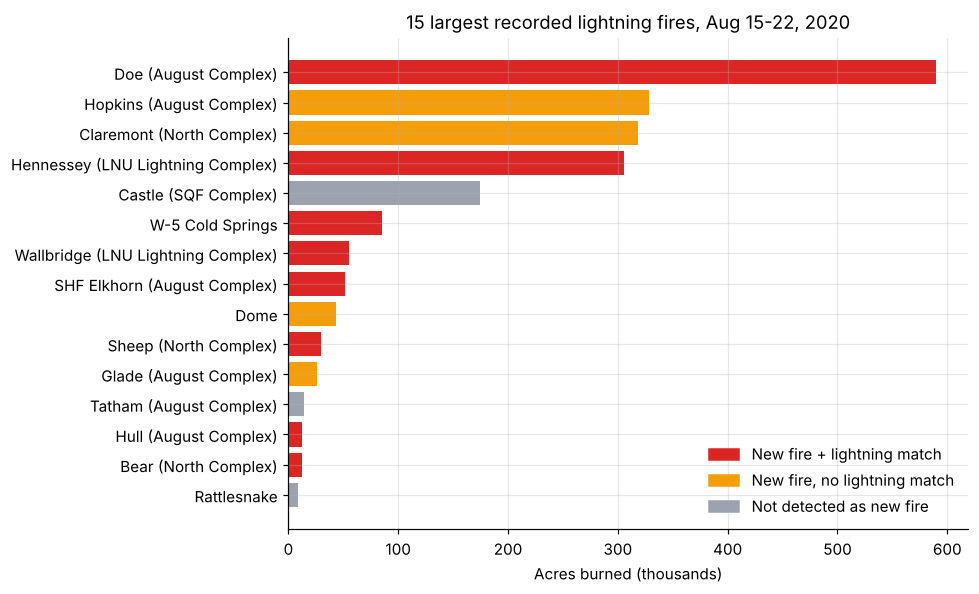

Seen as a new fire: 12 of 15; lightning-matched: 8 of 15; acres covered by lightning-matched fires: 1,140,630 of 2,054,293


fire,complex,discovered,acres,seen_as_new_fire,first_detection,lightning_matched,nearest_flash_km,flash_to_detection_h
Doe,August Complex,Aug 16,589368,yes,Aug 17 09:17 UTC,yes,3.900000,18.000000
Hopkins,August Complex,Aug 17,328363,yes,Aug 18 20:21 UTC,no,nan,nan
Claremont,North Complex,Aug 17,318776,yes,Aug 18 08:58 UTC,no,nan,nan
Hennessey,Lnu Lightning Complex,Aug 17,305651,yes,Aug 18 08:59 UTC,yes,2.100000,19.400000
Castle,Sqf Complex,Aug 19,174178,no,nan,no,nan,nan
W-5 Cold Springs,nan,Aug 18,84817,yes,Aug 18 20:21 UTC,yes,3.600000,26.700000
Wallbridge,Lnu Lightning Complex,Aug 17,55209,yes,Aug 18 10:39 UTC,yes,0.700000,10.500000
Shf Elkhorn,August Complex,Aug 18,51577,yes,Aug 19 10:20 UTC,yes,2.700000,38.400000
Dome,nan,Aug 15,43273,yes,Aug 16 09:37 UTC,no,nan,nan
Sheep,North Complex,Aug 17,29570,yes,Aug 17 20:40 UTC,yes,3.400000,4.400000


In [13]:
named = load("named_fires.csv")
named["status"] = np.select(
    [named.lightning_matched == "yes", named.seen_as_new_fire == "yes"],
    ["New fire + lightning match", "New fire, no lightning match"], "Not detected as new fire")
colors = {"New fire + lightning match": RED, "New fire, no lightning match": ORANGE, "Not detected as new fire": GREY}

n = named.iloc[::-1]
fix = lambda t: t.replace("Lnu", "LNU").replace("Sqf", "SQF").replace("Shf", "SHF")
labels = [fix(f"{f} ({c})" if isinstance(c, str) and c else f) for f, c in zip(n.fire, n.complex)]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(labels, n.acres / 1000, color=[colors[s] for s in n.status])
ax.set(xlabel="Acres burned (thousands)", title="15 largest recorded lightning fires, Aug 15-22, 2020")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=col, label=s) for s, col in colors.items()], loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

print(f"Seen as a new fire: {(named.seen_as_new_fire == 'yes').sum()} of {len(named)}; "
      f"lightning-matched: {(named.lightning_matched == 'yes').sum()} of {len(named)}; "
      f"acres covered by lightning-matched fires: "
      f"{named.loc[named.lightning_matched == 'yes', 'acres'].sum():,} of {named.acres.sum():,}")
named.drop(columns="status").style.hide(axis="index")

12 of the 15 largest fires were seen as new fires, and 8 were matched to lightning. Those 8 cover about 1.14 million of the 2.05 million acres (56%), including Doe, the largest fire in the study window (August Complex, 589,368 acres). Four large fires were seen but had no flash within 5 km and 48 h, consistent with the recall limits in section 6.

## 9. Broader evaluation: Aug 15–25 and CAL FIRE perimeters

`broad_eval.py` reruns the same rules with lightning data for Aug 21–25 (36,948 more flashes) and checks the results against a second ground truth: CAL FIRE fire perimeters for 2020 (`fire_perimeters_ca2020.geojson`, 503 perimeters). A pipeline fire counts if it lies inside a perimeter or within 1 km of its edge.

window,fod_fires,fod_fires_10plus_acres,new_fires,new_fires_with_glm,lightning_matched,precision_all,precision_lightning,recall_all,recall_lightning,recall_all_10plus,recall_lightning_10plus,match_rate_with_glm,f1_all,f1_lightning
Aug 15-Aug 22 (original),242,60,139,115,65,0.230000,0.385000,0.190000,0.161000,0.483000,0.367000,0.452000,0.208000,0.227000
Aug 15-Aug 25 (extended),268,65,159,135,70,0.220000,0.386000,0.183000,0.153000,0.477000,0.369000,0.422000,0.200000,0.219000
Aug 23-25 (new days only),26,5,20,20,5,0.150000,0.400000,0.115000,0.077000,0.400000,0.400000,0.250000,0.130000,0.129000


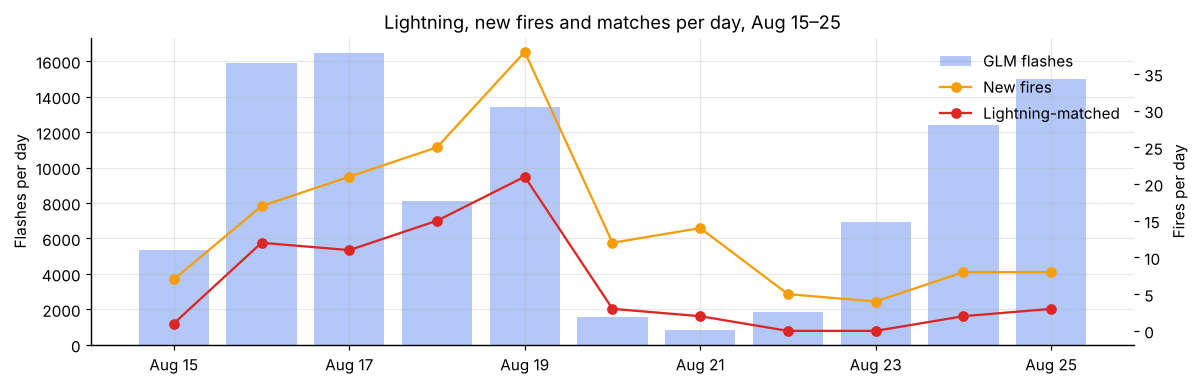

In [14]:
summary = load("broad_eval_summary.csv")
display(summary.style.hide(axis="index"))

day = load("broad_eval_by_day.csv")
day["day"] = pd.to_datetime(day["day"])
fig, ax1 = plt.subplots(figsize=(11, 3.6))
ax1.bar(day.day, day.glm_flashes, color=BLUE, alpha=0.35, width=0.8, label="GLM flashes")
ax1.set_ylabel("Flashes per day")
ax2 = ax1.twinx()
ax2.plot(day.day, day.new_fires, "o-", color=ORANGE, label="New fires")
ax2.plot(day.day, day.lightning_matched, "o-", color=RED, label="Lightning-matched")
ax2.set_ylabel("Fires per day"); ax2.grid(False)
ax1.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %d"))
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper right", frameon=False)
ax1.set_title("Lightning, new fires and matches per day, Aug 15–25")
plt.tight_layout(); plt.show()

Over the longer window, the lightning filter keeps precision at 38–40% against 22–23% without it, and recall for 10+ acre fires stays at 37%. A second lightning episode builds on Aug 23–25, but only 5 of 20 new fires on those days matched lightning; large siege fires were still spreading, so more "new" detections may be new parts of existing fires.

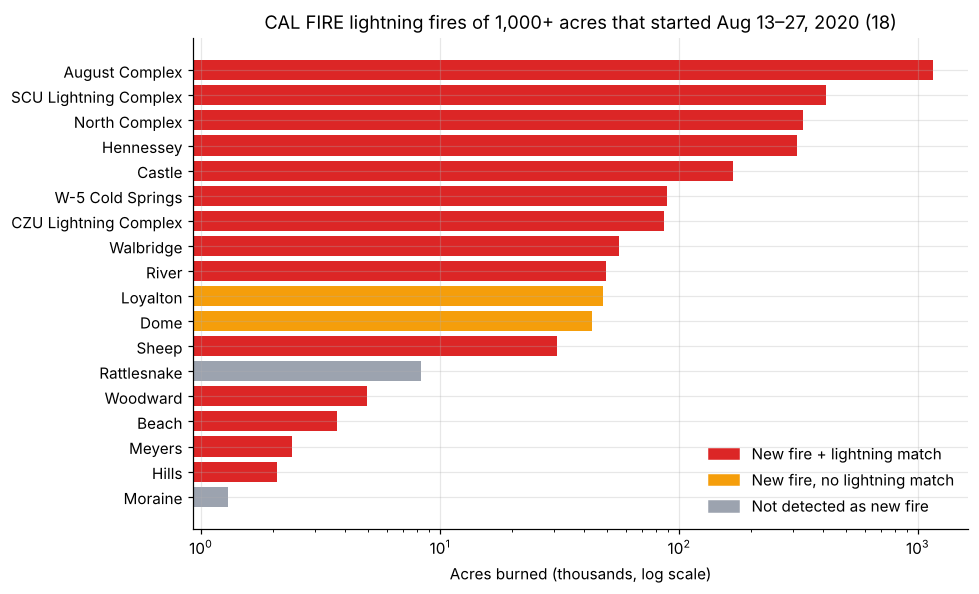

Detected as new fires: 16 of 18; lightning-matched: 14 of 18


name,acres,new_fires_inside,lightning_matched_inside,first_new_fire,first_lightning_match
AUGUST COMPLEX,"1,153,175",16,13,2020-08-17 09:17:00,2020-08-17 09:17:00
SCU LIGHTNING COMPLEX,"412,976",9,7,2020-08-16 20:58:00,2020-08-16 20:58:00
HENNESSEY,"310,470",12,7,2020-08-18 08:59:00,2020-08-18 08:59:00
CZU LIGHTNING COMPLEX,"86,295",4,3,2020-08-16 20:58:00,2020-08-16 20:58:00
WALBRIDGE,"56,121",2,2,2020-08-18 10:39:00,2020-08-18 10:39:00
MEYERS,"2,394",1,1,2020-08-19 10:21:00,2020-08-19 10:21:00


In [15]:
per = load("perimeter_results.csv")
light = per[(per.lightning) & (per.in_window)]
big = light[light.acres >= 1000].sort_values("acres")
status = np.select([big.lightning_matched_inside > 0, big.new_fires_inside > 0],
                   ["New fire + lightning match", "New fire, no lightning match"], "Not detected as new fire")
colors = {"New fire + lightning match": RED, "New fire, no lightning match": ORANGE, "Not detected as new fire": GREY}
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(big.name.str.title().str.replace("Scu ", "SCU ").str.replace("Czu ", "CZU "), big.acres / 1000, color=[colors[s] for s in status])
ax.set(xscale="log", xlabel="Acres burned (thousands, log scale)",
       title=f"CAL FIRE lightning fires of 1,000+ acres that started Aug 13–27, 2020 ({len(big)})")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=s) for s, c in colors.items()], loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

print(f"Detected as new fires: {(big.new_fires_inside > 0).sum()} of {len(big)}; "
      f"lightning-matched: {(big.lightning_matched_inside > 0).sum()} of {len(big)}")
cx = per[per.name.str.contains("AUGUST COMPLEX|SCU LIGHTNING|CZU LIGHTNING|HENNESSEY|WALBRIDGE|MEYERS")]
display(cx[["name", "acres", "new_fires_inside", "lightning_matched_inside", "first_new_fire", "first_lightning_match"]]
        .style.hide(axis="index").format({"acres": "{:,.0f}"}))

Against CAL FIRE perimeters (Aug 15–25), 46% of all new fires fall inside a lightning-fire perimeter, against **76%** of lightning-matched fires: the same ~1.7x gain as against FPA FOD. 16 of the 18 large lightning fires were detected (only Rattlesnake and Moraine were missed), and the August, SCU, CZU and LNU complexes were all detected and matched within one to two days of the Aug 16–17 storms. FPA FOD has no records for SCU or CZU, so perimeters are the only ground truth for them. A perimeter shows a fire's final extent, so a detection inside one may be a new spot on a fire that was already burning.

## 10. MongoDB vs Snowflake

`snowflake_queries.sql` runs the same lookup (flashes within 5 km and the 48 h before each new fire) in Snowflake with `ST_DWITHIN`, on an X-Small warehouse with the result cache off.

query,run1_ms,run2_ms,run3_ms,median_total_ms,median_exec_ms,fires_matched,warehouse
all_fires_join,521,639,248,521,120,65.000000,X-Small
single_fire_lookup,281,431,346,346,107,nan,X-Small


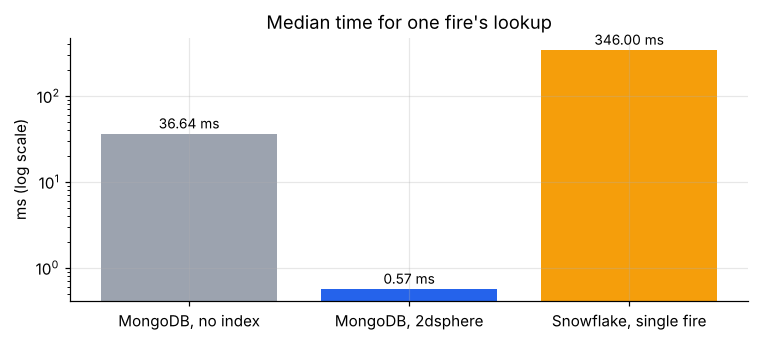

In [16]:
sf = load("snowflake_benchmark.csv")
display(sf.style.hide(axis="index"))
mongo_med = mongo.set_index("index").median_query_ms
comp = pd.Series({"MongoDB, no index": mongo_med.iloc[0], "MongoDB, 2dsphere": mongo_med.iloc[1],
                  "Snowflake, single fire": sf.set_index("query").loc["single_fire_lookup", "median_total_ms"]})
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(comp.index, comp.values, color=[GREY, BLUE, ORANGE])
ax.set(yscale="log", ylabel="ms (log scale)", title="Median time for one fire's lookup")
for i, v in enumerate(comp.values):
    ax.text(i, v * 1.15, f"{v:,.2f} ms", ha="center", fontsize=9)
plt.tight_layout(); plt.show()

Snowflake matched the same 65 fires. A single-fire lookup took 346 ms, about 600x slower than an indexed MongoDB query (0.57 ms), and one join over all new fires took 521 ms. The warehouse suits batch analysis over many fires; MongoDB suits per-event lookups inside the stream.

## 11. Course techniques

`course_techniques.py` applies five course techniques to the same data, as a time-ordered pass that simulates a stream (full output in `course_techniques_output.txt`).

method,target_fp,bits,k,memory_kb,new_fires,us_per_event,agree_with_prototype,missed_vs_set
Exact Python set (same cell keys),-,nan,nan,362.300000,139,5.000000,139,nan
Bloom filter,0.01,41782.000000,7.000000,5.100000,125,26.900000,125,14.000000
Bloom filter,0.001,62672.000000,10.000000,7.700000,138,30.500000,138,1.000000
Bloom filter,0.0001,83563.000000,13.000000,10.200000,139,34.300000,139,0.000000


day,flashes,exact_distinct_cells,fm_estimate,rel_error_pct
2020-08-15,5341,3576,3560,-0.400000
2020-08-16,15894,11482,12563,9.400000
2020-08-17,16489,11414,12563,10.100000
2020-08-18,8127,5508,4409,-20.000000
2020-08-19,13400,8114,8467,4.400000
2020-08-20,1552,894,967,8.200000


k,L,avg_candidates,pct_of_all_flashes,pair_recall_pct,fire_recall_pct,build_s,query_ms
1,1,613,1.010000,69.700000,98.500000,0.070000,0.140000
1,2,2127,3.500000,97.500000,98.500000,0.170000,0.310000
1,4,2427,3.990000,99.700000,100.000000,0.200000,0.300000
1,8,5646,9.290000,100.000000,100.000000,0.380000,0.750000
1,16,15262,25.100000,100.000000,100.000000,0.840000,2.250000
2,1,59,0.100000,57.700000,90.800000,0.060000,0.030000
2,2,19,0.030000,87.300000,96.900000,0.110000,0.020000
2,4,107,0.180000,96.400000,100.000000,0.240000,0.050000
2,8,399,0.660000,99.400000,100.000000,0.460000,0.100000
2,16,323,0.530000,100.000000,100.000000,0.890000,0.170000


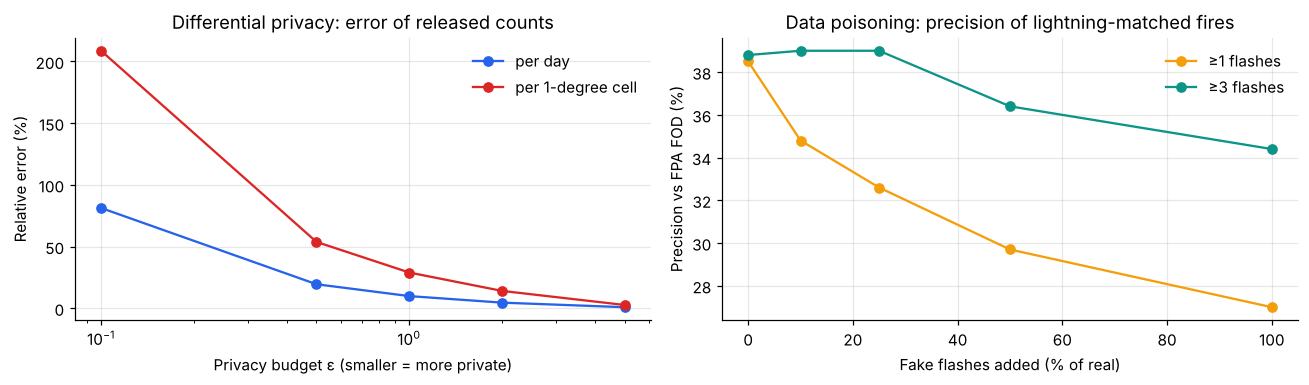

In [17]:
bloom = load("results_bloom.csv"); display(bloom.style.hide(axis="index"))
fm = load("results_fm.csv"); display(fm.style.hide(axis="index"))
lsh = load("results_lsh.csv"); display(lsh.style.hide(axis="index"))

dp = load("results_dp.csv"); poison = load("results_poison.csv")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for rel, col in [("per day", BLUE), ("per 1-degree cell", RED)]:
    d = dp[dp.release == rel]
    axes[0].plot(d.epsilon, d.rel_error_pct, "o-", color=col, label=rel)
axes[0].set(xscale="log", xlabel="Privacy budget ε (smaller = more private)", ylabel="Relative error (%)",
            title="Differential privacy: error of released counts")
axes[0].legend(frameon=False)
for rule, col in [(">=1 flashes", ORANGE), (">=3 flashes", TEAL)]:
    p = poison[poison.rule == rule]
    axes[1].plot(p.poison_rate * 100, p.precision_pct, "o-", color=col, label=rule.replace(">=", "≥"))
axes[1].set(xlabel="Fake flashes added (% of real)", ylabel="Precision vs FPA FOD (%)",
            title="Data poisoning: precision of lightning-matched fires")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

- **Bloom filter:** 10.2 KB instead of 362.3 KB (36x smaller) finds all 139 new fires at a 0.01% target false-positive rate. At 1% it misses 14, because each event does 200 lookups.
- **Flajolet–Martin:** distinct 1 km cells struck per day, within 8.8% on average.
- **LSH:** k = 2, L = 4 gives 107 candidate flashes per fire (0.18% of all flashes) with 100% fire recall.
- **Differential privacy:** ε = 1 adds about 10% error to daily counts but 29% to per-cell counts.
- **Poisoning:** requiring ≥3 flashes keeps precision at 34% when fake flashes equal 100% of real ones, against 27% for the ≥1-flash rule.

## 12. Status and next steps

All analysis steps are done: data (Aug 15–25), matching, baseline, tuning, FPA FOD validation and precision/recall sweep, streaming with in-stream new-fire detection, MongoDB and Snowflake queries, the broader evaluation with CAL FIRE perimeters, and the course techniques. The final report and slides are drafted.

Possible next steps:
- Replace the Spark detector's exact per-cell state with the Bloom filter, so memory stays fixed.
- Spread fire messages over several Kafka partitions without losing order.
- Extend to the full 2020 season and test a proximity index in place of a fixed D and T.

Details are in `README.md`.